# Assignment 06: A First-Principles Species Distribution Model

## BIO597 Spatial Analysis of Biodiversity

This assignment asks you to build and interpret a simple one-variable species distribution model without using an SDM package. You will choose one amphibian species, describe the environmental values at its occurrence records, compare those values with background environments, create a suitability curve, and project that curve across Maine.

## Deliverable

Submit a completed notebook with code, maps, plots, and short written interpretations. Your goal is to show that you understand the moving parts of an SDM before we use more automated modeling tools.

## Learning goals

By the end of this assignment, you should be able to:

* describe the difference between occurrence, background, and absence data
* extract one raster predictor at species occurrence records
* compare used environments with available environments
* create a simple environmental suitability score
* project a suitability score across raster space
* explain why a conceptual SDM is not the same as a validated prediction model

## Data

Use:

* `Amphibians_ME/Amphibians_ME.csv` for occurrence records
* `/home/jovyan/shared-readwrite/bioclim/` for one environmental variable of your choice that is NOT mean annual temperature
* `../labs/ME_ShapeFiles/Maine_State_Boundary.shp` for the Maine boundary

You may use the same species as the lab or choose a different species with at least 100 usable records.

## 1. Import packages

Import `pandas`, `geopandas`, `rioxarray`, `xarray`, `numpy`, `matplotlib.pyplot`, and `Path`.

In [1]:
import pandas as pd
import geopandas as gpd
import rioxarray as rxr
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

## 2. Load and combine the Maine boundary

Read the Maine state boundary shapefile, inspect its CRS and shape, and dissolve it to one row.

In [2]:
boundary_path = "../labs/ME_ShapeFiles/Maine_State_Boundary.shp"

# Read the boundary.
maine_boundary = gpd.read_file(boundary_path)
# Print its shape and CRS.
print(maine_boundary.shape)
print(maine_boundary.crs)
# Dissolve it to one row.
maine_boundary = maine_boundary.dissolve()
#maine_boundary.explore()

(6204, 10)
EPSG:4326


## 3. Open and clip environmental data

Select one environmental variable of your choosing that is NOT mean annual temperature. You can choose one you think will work well or one you think is less important for the study organism. Open the variable .tif file with `masked=True`, clip it to Maine, and remove the band dimension with `squeeze()`.


In [3]:
bioclim_path = Path("/home/jovyan/shared/bioclim")
bio19_path = bioclim_path / "wc2.1_2.5m_bio_19.tif"

# Open bio1 with rxr.open_rasterio().
bio19 = rxr.open_rasterio(
    bio19_path,
    masked=True,
)
# Clip it to the dissolved Maine boundary.
bio19_maine = bio19.rio.clip(
    maine_boundary.geometry,
    maine_boundary.crs,
    drop=True,
    from_disk=True,
)
# Squeeze out the band dimension.
bio19_maine = bio19_maine.squeeze()
# Check that units are in mm
bio19_maine.head()

# calculate statistics
maine_mean = bio19_maine.mean()
maine_sd = bio19_maine.std()

print(f"Number of usable records: {len(bio19_maine)}")
print(f"Mean occurrence precipitation value (mm): {maine_mean:.2f} C")
print(f"SD of occurrence precipitation value (mm): {maine_sd:.2f} C")
print(f"Minimum occurrence precipitation value (mm): {bio19_maine.min():.2f} C")
print(f"Maximum occurrence precipitation value (mm): {bio19_maine.max():.2f} C")

Number of usable records: 109
Mean occurrence precipitation value (mm): 246.69 C
SD of occurrence precipitation value (mm): 36.76 C
Minimum occurrence precipitation value (mm): 182.00 C
Maximum occurrence precipitation value (mm): 387.00 C


## 4. Map your environmental variable

Create a map of the clipped temperature raster. Include a title.

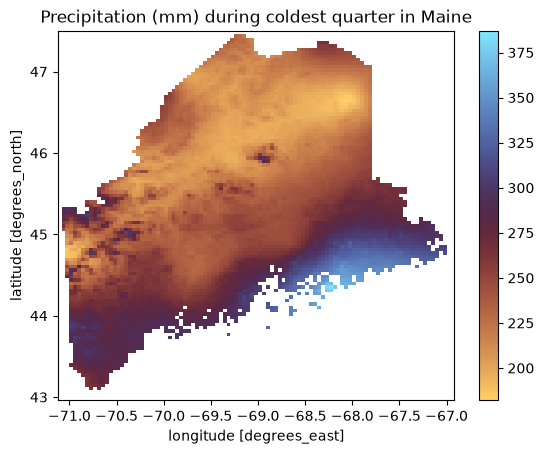

In [4]:
bio19_maine.plot(cmap="managua")
plt.title("Precipitation (mm) during coldest quarter in Maine")
plt.show()

## 5. Load and prepare amphibian occurrence records

Read the tab-delimited amphibian file. Keep `gbifID`, `species`, longitude, latitude, coordinate uncertainty, and year. Convert coordinates to numeric values and remove records missing species or coordinates.

In [5]:
amphibians = pd.read_csv(
    "Amphibians_ME/Amphibians_ME.csv",
    sep="\t",
    low_memory=False,
)

columns_to_keep = [
    "gbifID",
    "species",
    "decimalLongitude",
    "decimalLatitude",
    "coordinateUncertaintyInMeters",
    "year",
]

# Keep only columns_to_keep.
amphibians = amphibians[columns_to_keep].copy()
# Convert longitude and latitude to numeric values.
amphibians["decimalLongitude"] = pd.to_numeric(amphibians["decimalLongitude"], errors="coerce")
amphibians["decimalLatitude"] = pd.to_numeric(amphibians["decimalLatitude"], errors="coerce")
# Drop records missing species, longitude, or latitude.
amphibians = amphibians.dropna(subset=["species", "decimalLongitude", "decimalLatitude"]).copy()

# Reduce spatial imprecision (The "tulipifera-ike" filter!)
amphibians = amphibians[amphibians["coordinateUncertaintyInMeters"] < 200]

## 6. Choose one species

Display the most common species, then choose one species with at least 100 records. Store its scientific name as `target_species`.

In [6]:
# Display species counts.

amphibians["species"].value_counts().head(15)

species
Pseudacris crucifer          1839
Aquarana clamitans           1779
Anaxyrus americanus          1689
Boreorana sylvatica          1617
Lithobates catesbeianus      1487
Ambystoma maculatum          1317
Plethodon cinereus           1283
Lithobates palustris         1049
Dryophytes versicolor         790
Notophthalmus viridescens     611
Lithobates pipiens            326
Hemidactylium scutatum        233
Eurycea bislineata            192
Ambystoma laterale            165
Aquarana septentrionalis       80
Name: count, dtype: int64

In [7]:
target_species = "Eurycea bislineata"

# Filter the occurrence table to your target species.
presence = amphibians.loc[amphibians["species"] == target_species].copy()

# Display the number of records and the first five rows.
print(target_species)
print(presence.shape)
presence.head()

Eurycea bislineata
(192, 6)


,gbifID,species,decimalLongitude,decimalLatitude,coordinateUncertaintyInMeters,year
401,6500061937,Eurycea bislineata,-70.126280,43.857712,33.0,2026.0
421,6499991795,Eurycea bislineata,-70.127734,44.675833,3.0,2026.0
476,6499745855,Eurycea bislineata,-70.126380,43.857983,4.0,2026.0
615,6499012564,Eurycea bislineata,-70.127712,44.675864,9.0,2026.0
675,6498609637,Eurycea bislineata,-69.918260,45.629168,18.0,2026.0


**Why did you choose this species?** Include one sentence about record count and one sentence about why it may or may not be appropriate for this simple model. I chose this species because it has an adequate number of records to detect occupancy patterns, but hopefully few enough records that its presence is affected by the climate variable I chose. I chose to look at precipitation in the coldest quarter because salamanders require wet habitats for breeding, which occurs during spring as winter snow and ice are melting.

## 7. Create an occurrence GeoDataFrame

Use longitude and latitude to create point geometry. Assign `EPSG:4326`. Confirm that the occurrence CRS and raster CRS are compatible.

In [8]:
presence_gdf = gpd.GeoDataFrame(
    presence,
    geometry=gpd.points_from_xy(
        presence["decimalLongitude"],
        presence["decimalLatitude"],
    ),
    crs="EPSG:4326",
)

print("Occurrence CRS:", presence_gdf.crs)
print("Raster CRS:", bio19_maine.rio.crs)

Occurrence CRS: EPSG:4326
Raster CRS: EPSG:4326


**CRS check:** Explain why coordinate systems matter before extracting raster values at points. The two datasets must be the same CRS for them to be spatially joined, otherwise the geographic locations of the two datasets will not align appropriately.

## 8. Extract environment at occurrence points

Create `xarray.DataArray` objects for point longitude and latitude. Use `.sel(..., method="nearest")` to extract BIO1 values at occurrence records. Add the extracted values to a column named `bio1_c`.

In [9]:
# Create point_x and point_y.
point_x = xr.DataArray(presence_gdf.geometry.x.values, dims="record")
point_y = xr.DataArray(presence_gdf.geometry.y.values, dims="record")
# Extract precipitation values.
presence_precip = bio19_maine.sel(
    x=point_x,
    y=point_y,
    method="nearest",
)
# Add them to presence_gdf as bio19_mm.
presence_gdf["bio19_mm"] = presence_precip.values

# Drop records with missing bio1_c.
presence_gdf = presence_gdf.dropna(subset=["bio19_mm"]).copy()

# Rebuild point_x and point_y after dropping missing values.
point_x = xr.DataArray(presence_gdf.geometry.x.values, dims="record")
point_y = xr.DataArray(presence_gdf.geometry.y.values, dims="record")

presence_gdf[["species", "decimalLongitude", "decimalLatitude", "bio19_mm"]].head()

,species,decimalLongitude,decimalLatitude,bio19_mm
401,Eurycea bislineata,-70.126280,43.857712,291.0
421,Eurycea bislineata,-70.127734,44.675833,259.0
476,Eurycea bislineata,-70.126380,43.857983,291.0
615,Eurycea bislineata,-70.127712,44.675864,259.0
675,Eurycea bislineata,-69.918260,45.629168,203.0


## 9. Summarize occurrence environment

Calculate the count, mean, standard deviation, minimum, and maximum of `bio1_c` at occurrence records.

In [10]:
presence_mean = presence_gdf["bio19_mm"].mean()
presence_sd = presence_gdf["bio19_mm"].std()

print(f"Number of usable records: {len(presence_gdf)}")
print(f"Mean occurrence precipitation value (mm): {presence_mean:.2f} C")
print(f"SD of occurrence precipitation value (mm): {presence_sd:.2f} C")
print(f"Minimum occurrence precipitation value (mm): {presence_gdf['bio19_mm'].min():.2f} C")
print(f"Maximum occurrence precipitation value (mm): {presence_gdf['bio19_mm'].max():.2f} C")

Number of usable records: 184
Mean occurrence precipitation value (mm): 263.80 C
SD of occurrence precipitation value (mm): 30.22 C
Minimum occurrence precipitation value (mm): 193.00 C
Maximum occurrence precipitation value (mm): 387.00 C


**Interpretation:** In two or three sentences, describe the environmental range represented by your species records. This species appears to have a relatively SD, but the minimum and maximum of its precipitation range is almost identical to the min/max of the precipitation dataset for the entire state. The mean precip value for the occurrence records (263) is higher than the mean for the entire state (246). This suggests that this species may be less likely to occur in enviornments with drier cold months.

## 10. Sample background environment

Create a random sample of up to 5,000 valid cells from Maine for your environmental variable. Use a random seed so your results are reproducible.

In [11]:
rng = np.random.default_rng(597)

# Create an array of valid raster environmental values.
valid_precip = bio19_maine.values
valid_precip = valid_precip[np.isfinite(valid_precip)]

# Randomly sample up to 5000 cells without replacement.
background_precip = rng.choice(
    valid_precip,
    size=min(5000, valid_precip.size),
    replace=False,
)

# Print the background sample size, mean, and standard deviation.
print(f"Background sample size: {len(background_precip)}")
print(f"Mean background precipitation: {background_precip.mean():.2f} mm")
print(f"SD background precipitation: {background_precip.std():.2f} mm")

Background sample size: 5000
Mean background precipitation: 246.42 mm
SD background precipitation: 36.81 mm


## 11. Compare occurrence and background environments

Make overlapping histograms of occurrence environment and background environment. Use density-scaled histograms so the shapes can be compared even though the sample sizes differ.

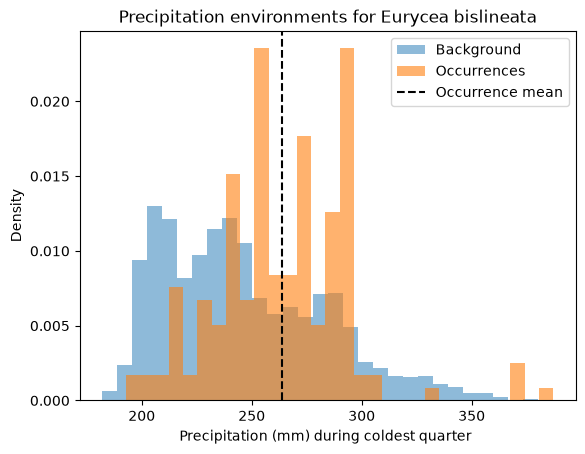

In [12]:
plt.hist(background_precip, bins=30, alpha=0.5, density=True, label="Background")
plt.hist(presence_gdf["bio19_mm"], bins=30, alpha=0.6, density=True, label="Occurrences")
plt.axvline(presence_mean, color="black", linestyle="--", label="Occurrence mean")
plt.xlabel("Precipitation (mm) during coldest quarter ")
plt.ylabel("Density")
plt.title(f"Precipitation environments for {target_species}")
plt.legend()
plt.show()

**Interpretation:** Does your species appear to use a narrow or broad subset of available environmental space? Explain using your plot. It appears to use a much borader subset of the available environmental space than I predicted (i.e., the range of values is similar to that of the background range), but the highest density of occurrences are at values above the background mean.

## 12. Define a suitability function

Write a function that takes `observed`, `optimum`, and `tolerance` and returns:

```python
np.exp(-0.5 * ((observed - optimum) / tolerance) ** 2)
```

This creates a score near 1 when observed environment is close to the optimum and closer to 0 as temperature gets farther away.

In [13]:
def environmental_suitability(observed, optimum, tolerance):
    z = (observed - optimum) / tolerance
    return np.exp(-0.5 * z**2)

## 13. Plot your suitability curve

Use the mean occurrence environmental value as the optimum and the standard deviation of occurrence as the tolerance. Plot suitability across the full range of Maine BIO1 values.

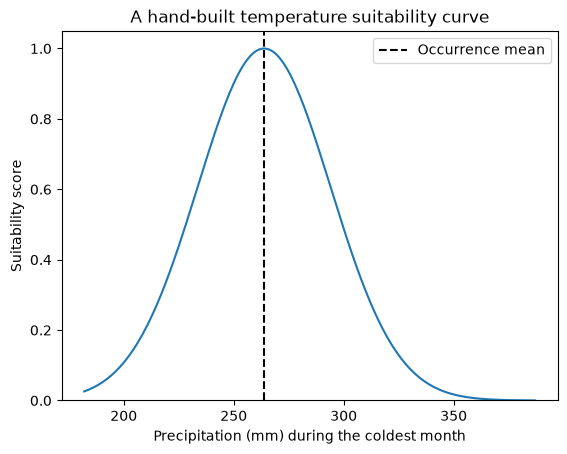

In [14]:
# Calculate presence_mean and presence_sd.
presence_mean = presence_gdf["bio19_mm"].mean()
presence_sd = presence_gdf["bio19_mm"].std()

# Create a sequence of environmental values across the raster range.
x_precip = np.linspace(
    float(np.nanmin(bio19_maine.values)),
    float(np.nanmax(bio19_maine.values)),
    200, 
)

# Calculate suitability for those values.
suitability_curve = environmental_suitability(
    x_precip,
    optimum=presence_mean,
    tolerance=presence_sd,
)

# Plot the curve.
plt.plot(x_precip, suitability_curve)
plt.axvline(presence_mean, color="black", linestyle="--", label="Occurrence mean")
plt.xlabel("Precipitation (mm) during the coldest month")
plt.ylabel("Suitability score")
plt.ylim(0, 1.05)
plt.title("A hand-built temperature suitability curve")
plt.legend()
plt.show()

**Interpretation:** What value receives the highest suitability score? What does the tolerance control? The highest suitability is when the coldest month receives ~260 mm of precipitation. Tolerance controls the width of the curve (higher tolerance = wider, lower tolerance = narrower).

## 14. Project suitability across Maine

Apply your suitability function to every cell in the environmental raster. Keep missing raster cells missing.

In [15]:
# Use xr.apply_ufunc() to apply environmental_suitability to the raster.
# Store the result as suitability.
suitability = xr.apply_ufunc(
    environmental_suitability,
    bio19_maine,
    presence_mean,
    presence_sd,
)

# Mask cells where the environmental raster is missing.
suitability = suitability.where(np.isfinite(bio19_maine))
suitability = suitability.rio.write_crs(bio19_maine.rio.crs)
suitability.name = "environmental_suitability"

## 15. Map suitability

Create a continuous suitability map with values from 0 to 1.

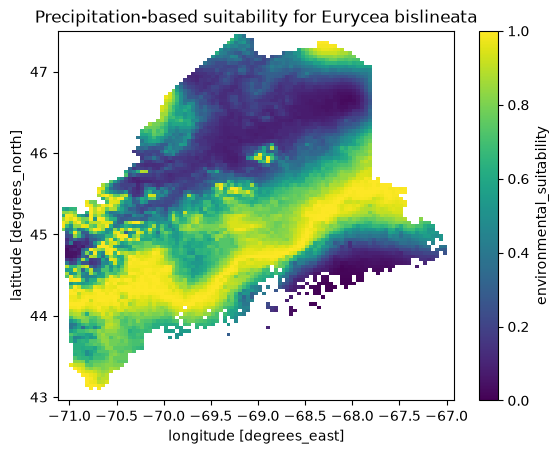

In [16]:
suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Precipitation-based suitability for {target_species}")
plt.show()

## 16. Overlay occurrence points

Plot your suitability raster and overlay the occurrence points. This is a visual check, not a formal validation.

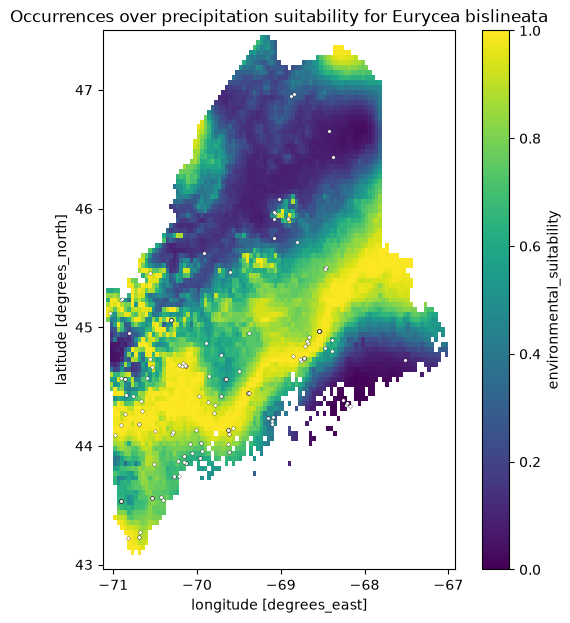

In [17]:
fig, ax = plt.subplots(figsize=(7, 7))
suitability.plot(ax=ax, vmin=0, vmax=1, cmap="viridis")
presence_gdf.plot(ax=ax, markersize=6, color="white", edgecolor="black", linewidth=0.2)
ax.set_title(f"Occurrences over precipitation suitability for {target_species}")
plt.show()

**Visual check:** Do occurrence points generally fall in areas with higher predicted suitability? Describe any mismatch you see. For the most part, yes. There are two occurrences in the north that fall in a low-suitability environment, plus a few downeast near the coast.

## 17. Compare occurrence and background suitability scores

Extract suitability at occurrence records. Also calculate suitability for your background environmental values. Compare the two distributions with histograms.

Mean occurrence suitability: 0.744
Mean background suitability: 0.539


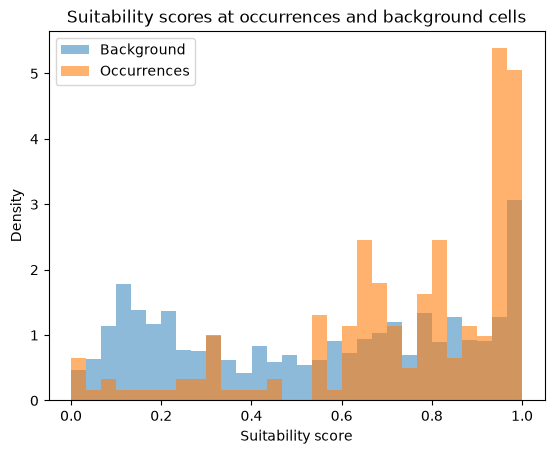

In [18]:
# Extract suitability at occurrence points.
presence_suitability = suitability.sel(
    x=point_x,
    y=point_y,
    method="nearest",
).values
# Calculate suitability for background environmental values.
background_suitability = environmental_suitability(
    background_precip,
    optimum=presence_mean,
    tolerance=presence_sd,
)
# Print mean occurrence suitability and mean background suitability.
print(f"Mean occurrence suitability: {np.nanmean(presence_suitability):.3f}")
print(f"Mean background suitability: {np.nanmean(background_suitability):.3f}")
# Plot overlapping histograms.
plt.hist(background_suitability, bins=30, alpha=0.5, density=True, label="Background")
plt.hist(presence_suitability, bins=30, alpha=0.6, density=True, label="Occurrences")
plt.xlabel("Suitability score")
plt.ylabel("Density")
plt.title("Suitability scores at occurrences and background cells")
plt.legend()
plt.show()

**Interpretation:** Did your model score occurrence records higher than background locations? What would it mean if it did not? For the most part, yes, but some occurrences had low suitability scores in the 0.2-0.4 range.

## 18. Change the tolerance

Create two additional suitability rasters: one with half the observed standard deviation and one with twice the observed standard deviation. Map all three side by side.

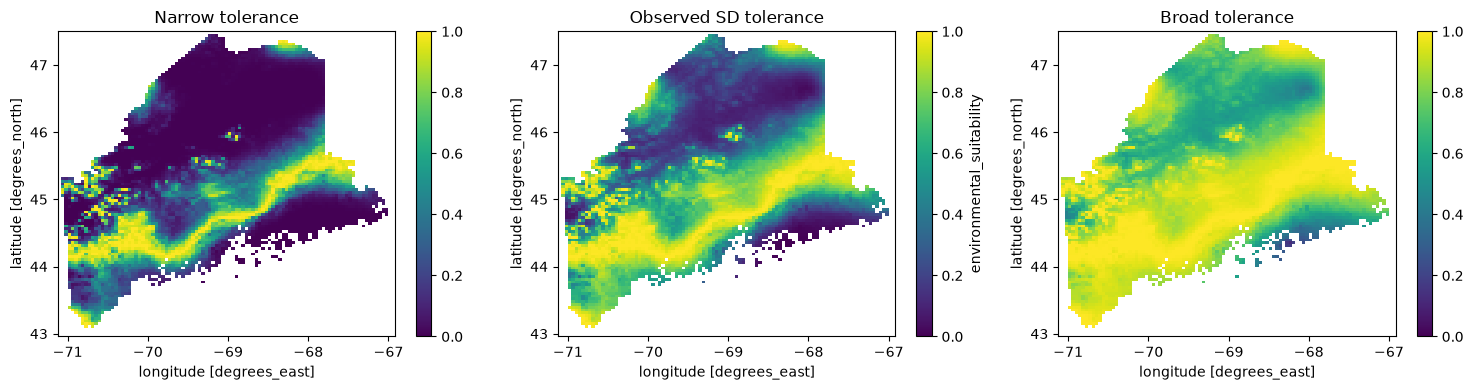

In [19]:
# Create narrow_suitability using presence_sd / 2.
narrow_suitability = xr.apply_ufunc(
    environmental_suitability,
    bio19_maine,
    presence_mean,
    presence_sd / 2,
).where(np.isfinite(bio19_maine))

# Create broad_suitability using presence_sd * 2.
broad_suitability = xr.apply_ufunc(
    environmental_suitability,
    bio19_maine,
    presence_mean,
    presence_sd * 2,
).where(np.isfinite(bio19_maine))

# Plot narrow, original, and broad suitability maps side by side.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
narrow_suitability.plot(ax=axes[0], vmin=0, vmax=1, cmap="viridis")
axes[0].set_title("Narrow tolerance")
suitability.plot(ax=axes[1], vmin=0, vmax=1, cmap="viridis")
axes[1].set_title("Observed SD tolerance")
broad_suitability.plot(ax=axes[2], vmin=0, vmax=1, cmap="viridis")
axes[2].set_title("Broad tolerance")
plt.tight_layout()
plt.show()

**Interpretation:** How does tolerance affect the predicted distribution? Which tolerance seems most defensible for your species, and why? The higher the tolerance level, the higher probability of suitable habitat is across the state. A tolerance value equal to the SD seems most defensible for because at this point I don't know much about the ecology, but if I learn more about its tolerance to wetter/drier environments, I may adjust the tolerance accordingly. I could also see adjusting the tolerance to allow for higher precip values but not for lower precip values.

## 19. Threshold the continuous map

Convert your continuous suitability map to a binary suitable/unsuitable map using a threshold of your choice. Report the fraction of Maine climate cells labeled suitable.

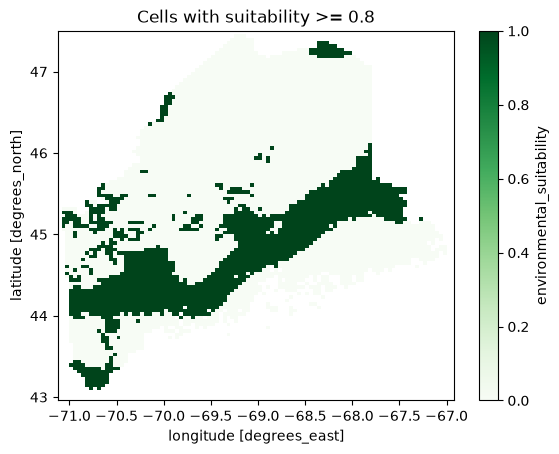

Fraction of Maine climate cells labeled suitable: 27.97%


In [20]:
threshold = 0.8

# Create a binary suitability map.
suitable_binary = suitability >= threshold
suitable_binary = suitable_binary.where(np.isfinite(bio19_maine))
# Plot it.
suitable_binary.plot(cmap="Greens")
plt.title(f"Cells with suitability >= {threshold}")
plt.show()
# Calculate the fraction of non-missing cells labeled suitable.
suitable_fraction = float(suitable_binary.mean(skipna=True))
print(f"Fraction of Maine climate cells labeled suitable: {suitable_fraction:.2%}")

**Threshold justification:** Why did you choose this threshold? How would the map change with a lower or higher threshold? I chose 80% as my threshold because that is commonly reported in Bayesian analysis papers I've read. I think it represents a good balance between being conservative about ecological inference while also wanting to allow for uncertainty. If I was using this map to give general recommendations on where to look for salamanders, I might use a lower threshold, whereas if I was using the map to inform policy, I may use a higher threshold to be more conservative.

## 20. Save your outputs

Save your continuous suitability raster as `Assignment06_suitability.tif`. Save a CSV containing your occurrence records and extracted BIO1 values as `Assignment06_presence.csv`.

In [21]:
# Save the suitability raster.
suitability.rio.to_raster("Assignment06_precip_suitability.tif")
# Save the occurrence table with extracted temperature values.
presence_table = presence_gdf.drop(columns="geometry")
presence_table["precip_suitability"] = presence_suitability
presence_table.to_csv("Assignment06_presence_precip_suitability.csv", index=False)

## Final reflection

Answer each question in two or three sentences.

1. In this exercise, what information came from occurrence records and what information came from the environmental raster? Presence information about the species, and the geographic coordinates for presence observations, came from the occurrence records. The actual amount of precipitation in each location on the map came from the environmental raster. 
2. Why did we compare occurrence environment with background environment? We wanted to know whether we could infer a relationship between the environmental parameter and occurrence just by looking at the raw data. Sometimes, a pattern arises that can foreshadow model results, such as if higher frequencies of occurrences are seen at background values that are not the highest frequency.
3. Why is this suitability score not the same as probability of presence? There are several factors that go into predicting presence, such as other environmental factores and detection probability. This suitability score predicts the suitability of the habitat based on a single environmental variable but does not consider any other parameters that affect the actual presence of the species.
4. Name two ecological or sampling processes ignored by this one-variable model. Temperature was not considered and likely plays a role in environmental suitability. Effort was also not considered and may affect patterns in the spatial distribution of observations.
5. What would a full SDM package add beyond this first-principles workflow? Handling of multiple variables and their interactions, multiple process levels (e.g., ecological and observation processes), non-linear relationships.

## Submit your work

Run the notebook from top to bottom. Make sure all maps, plots, saved files, and written answers are complete. Then commit and push the completed notebook to your class GitHub repository.

```bash
git add docs/assignments/Assignment-06-FirstPrinciplesSDM.ipynb
git commit -m "Complete first principles SDM assignment"
git push
```